# Autoencoder for Persistence Images

This notebook loads persistence images from `.npy` files, visualizes them, trains a convolutional autoencoder, and saves the trained model and sample reconstructions.

In [3]:
import numpy as np
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
import wandb
import umap

plt.rcParams['figure.figsize'] = (6, 6)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cpu


In [4]:
class PersistenceImageDataset(Dataset):
    def __init__(self, file_paths, normalize=True):
        self.file_paths = list(file_paths)
        self.normalize = normalize
        if len(self.file_paths) == 0:
            raise ValueError('No .npy files found for persistence-image dataset.')

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, index):
        path = self.file_paths[index]
        image = np.load(path)
        image = image.astype(np.float32)
        if image.ndim == 2:
            image = image[np.newaxis, ...]  # 1xHxW
        elif image.ndim == 3 and image.shape[-1] == 1:
            image = image.transpose(2, 0, 1)
        elif image.ndim == 3 and image.shape[0] != 1:
            image = image.transpose(2, 0, 1) if image.shape[2] == 1 else image
        elif image.ndim != 3:
            raise ValueError(f'Unsupported image shape: {image.shape}')

        if self.normalize:
            min_val = float(image.min())
            max_val = float(image.max())
            denom = max_val - min_val if max_val > min_val else 1.0
            image = (image - min_val) / denom

        return torch.from_numpy(image), path.name


## Load persistence image files

The loader attempts to read `cell_0_adf_pimage.npy` and `cell_0_rdf_pimage.npy` if present. If not, it searches for `.npy` files inside the notebook working directory and any `data/` subfolder.

In [5]:
# Find the project root by looking for results/persistent_diagrams
import os
current_dir = Path.cwd()
print(f'Initial working directory: {current_dir}')

# Try to find persistent_diagrams directory
pimage_dir = None
search_root = current_dir

# Check if we're already in the project root
if (current_dir / 'results' / 'persistent_diagrams').exists():
    workspace_root = current_dir
    pimage_dir = workspace_root / 'results' / 'persistent_diagrams'
else:
    # Try parent directory (in case notebook is in src/)
    if (current_dir.parent / 'results' / 'persistent_diagrams').exists():
        workspace_root = current_dir.parent
        pimage_dir = workspace_root / 'results' / 'persistent_diagrams'
    # Try going up two levels
    elif (current_dir.parent.parent / 'results' / 'persistent_diagrams').exists():
        workspace_root = current_dir.parent.parent
        pimage_dir = workspace_root / 'results' / 'persistent_diagrams'

if pimage_dir is None or not pimage_dir.exists():
    raise FileNotFoundError(f'Could not find results/persistent_diagrams directory.\nSearched from: {current_dir}')

print(f'Found project root: {workspace_root}')
print(f'Persistence image directory: {pimage_dir}')

# Load persistence images
file_paths = sorted(pimage_dir.glob('**/cell_*_*pimage.npy'))

if len(file_paths) == 0:
    raise FileNotFoundError(f'No persistence-image .npy files found.\nSearched in: {pimage_dir}\nExpected pattern: cID_*/cell_*_adf_pimage.npy or cell_*_rdf_pimage.npy')

print(f'\nFound {len(file_paths)} persistence image files')
for path in file_paths[:20]:
    print(' -', path.relative_to(workspace_root))
if len(file_paths) > 20:
    print(f' ... and {len(file_paths) - 20} more')

image_examples = [np.load(path) for path in file_paths[:6]]
print('\nSample shapes:')
for path, arr in zip(file_paths[:6], image_examples):
    print(f'{path.name}: shape={arr.shape}, min={float(arr.min()):.4f}, max={float(arr.max()):.4f}')


Initial working directory: /Users/ploypusee/Library/CloudStorage/GoogleDrive-ploy.polyluna@gmail.com/My Drive/2 Work/Research/01 Active Project/TDA Cell Classification/src/PMA_cells
Found project root: /Users/ploypusee/Library/CloudStorage/GoogleDrive-ploy.polyluna@gmail.com/My Drive/2 Work/Research/01 Active Project/TDA Cell Classification
Persistence image directory: /Users/ploypusee/Library/CloudStorage/GoogleDrive-ploy.polyluna@gmail.com/My Drive/2 Work/Research/01 Active Project/TDA Cell Classification/results/persistent_diagrams

Found 798 persistence image files
 - results/persistent_diagrams/cID_0/cell_0_adf_pimage.npy
 - results/persistent_diagrams/cID_0/cell_0_rdf_pimage.npy
 - results/persistent_diagrams/cID_1/cell_1_adf_pimage.npy
 - results/persistent_diagrams/cID_1/cell_1_rdf_pimage.npy
 - results/persistent_diagrams/cID_10/cell_10_adf_pimage.npy
 - results/persistent_diagrams/cID_10/cell_10_rdf_pimage.npy
 - results/persistent_diagrams/cID_100/cell_100_adf_pimage.npy
 - 

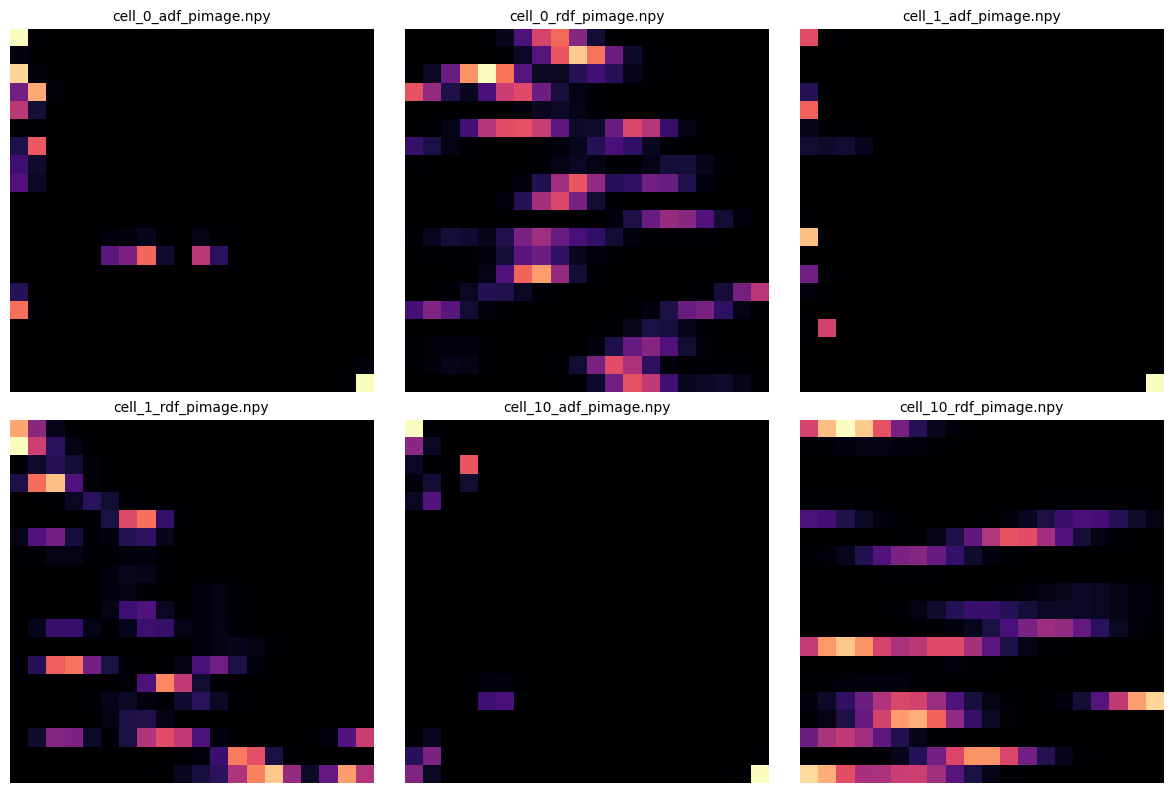

In [6]:
def plot_image_grid(images, titles=None, cmap='magma', ncols=3):
    n = len(images)
    ncols = min(ncols, n)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for idx, image in enumerate(images):
        arr = np.asarray(image)
        if arr.ndim == 3 and arr.shape[0] == 1:
            arr = arr[0]
        axes[idx].imshow(arr, cmap=cmap, origin='lower')
        axes[idx].axis('off')
        if titles is not None and idx < len(titles):
            axes[idx].set_title(titles[idx], fontsize=10)
    for j in range(idx + 1, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()
plot_image_grid([np.asarray(img) for img in image_examples], titles=[p.name for p in file_paths[:6]], ncols=3)


## Build the dataset and dataloader

Create a PyTorch dataset from the loaded `.npy` persistence images and prepare a training data loader. The dataset normalizes each image individually to `[0,1]`.

In [7]:
dataset = PersistenceImageDataset(file_paths)
print('Dataset size:', len(dataset))
image, filename = dataset[0]
print('Single image tensor shape:', tuple(image.shape), 'filename:', filename)
batch_size = 16
train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=False)
print('Batch size:', batch_size, 'num batches:', len(train_loader))


Dataset size: 798
Single image tensor shape: (1, 20, 20) filename: cell_0_adf_pimage.npy
Batch size: 16 num batches: 50


## Autoencoder architecture

Use a lightweight convolutional autoencoder that preserves the 2D persistence image shape. This architecture can reconstruct 20×20, 28×28, or similar square persistence-image sizes.

In [8]:
class ConvAutoencoder(nn.Module):
    def __init__(self, in_channels=1):
        super().__init__()
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        self.enc2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        self.enc3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.pool = nn.MaxPool2d(2, 2)

        self.tconv1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.bn_up1 = nn.BatchNorm2d(64)
        self.tconv2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.bn_up2 = nn.BatchNorm2d(32)
        self.dec_final = nn.Conv2d(32, in_channels, kernel_size=3, padding=1)

    def forward(self, x):
        x = self.enc1(x)
        x = self.pool(x)
        x = self.enc2(x)
        x = self.pool(x)
        x = self.enc3(x)

        x = F.relu(self.bn_up1(self.tconv1(x)))
        x = F.relu(self.bn_up2(self.tconv2(x)))
        x = self.dec_final(x)
        return torch.sigmoid(x)

    def encode(self, x):
        x = self.enc1(x)
        x = self.pool(x)
        x = self.enc2(x)
        x = self.pool(x)
        x = self.enc3(x)
        return x

model = ConvAutoencoder(in_channels=1).to(DEVICE)
print(model)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

run = wandb.init(
    project="TDA-Cell-Classification",
    name="Autoencoder-PersistenceImage",
    config={
        "architecture": "ConvAutoencoder",
        "dataset": "persistence_images",
        "image_size": 20,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "optimizer": "Adam",
        "loss": "MSELoss",
        "n_epochs": 20,
        "device": str(DEVICE),
    }
)
print(f"W&B run initialized: {run.name}")


ConvAutoencoder(
  (enc1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (enc2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (enc3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (tconv1): ConvTranspose2d(128, 64, kernel_size=(2, 2), stride=(2, 2))
  (bn_up1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (tconv2): ConvTranspose2d(64, 32, kernel_size=(2, 2), stride=(2, 2))
  (bn_up

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /Users/ploypusee/.netrc.
wandb: Currently logged in as: ployphusri (ployphusriubc) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B run initialized: Autoencoder-PersistenceImage


## Train the autoencoder

Run training and collect loss statistics. The losses are plotted at the end of training for monitoring convergence.

Epoch 01/20 - Loss: 0.047378
Epoch 02/20 - Loss: 0.012054
Epoch 03/20 - Loss: 0.008361
Epoch 04/20 - Loss: 0.006605
Epoch 05/20 - Loss: 0.005288
Epoch 06/20 - Loss: 0.004398
Epoch 07/20 - Loss: 0.003665
Epoch 08/20 - Loss: 0.003119
Epoch 09/20 - Loss: 0.002791
Epoch 10/20 - Loss: 0.002597
Epoch 11/20 - Loss: 0.002303
Epoch 12/20 - Loss: 0.002133
Epoch 13/20 - Loss: 0.001962
Epoch 14/20 - Loss: 0.001860
Epoch 15/20 - Loss: 0.001763
Epoch 16/20 - Loss: 0.001615
Epoch 17/20 - Loss: 0.001489
Epoch 18/20 - Loss: 0.001461
Epoch 19/20 - Loss: 0.001395
Epoch 20/20 - Loss: 0.001307


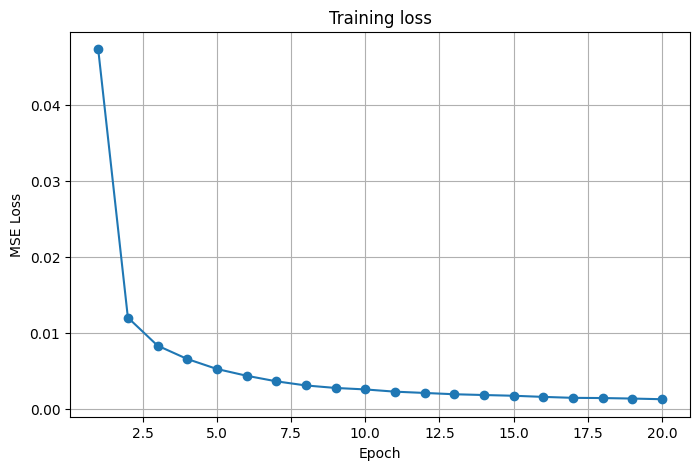

In [28]:
n_epochs = 20
train_losses = []
for epoch in range(1, n_epochs + 1):
    model.train()
    running_loss = 0.0
    for batch, _ in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        recon = model(batch)
        loss = criterion(recon, batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * batch.size(0)
    epoch_loss = running_loss / len(dataset)
    train_losses.append(epoch_loss)
    print(f'Epoch {epoch:02d}/{n_epochs} - Loss: {epoch_loss:.6f}')
    
    # Log to W&B
    wandb.log({
        "epoch": epoch,
        "train_loss": epoch_loss,
    })

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o')
plt.title('Training loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True)

# Log training loss chart to W&B
wandb.log({"training_loss_chart": wandb.Image(plt)})
plt.show()


/Users/ploypusee/Library/CloudStorage/GoogleDrive-ploy.polyluna@gmail.com/My Drive/2 Work/Research/01 Active Project/TDA Cell Classification/.venv/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


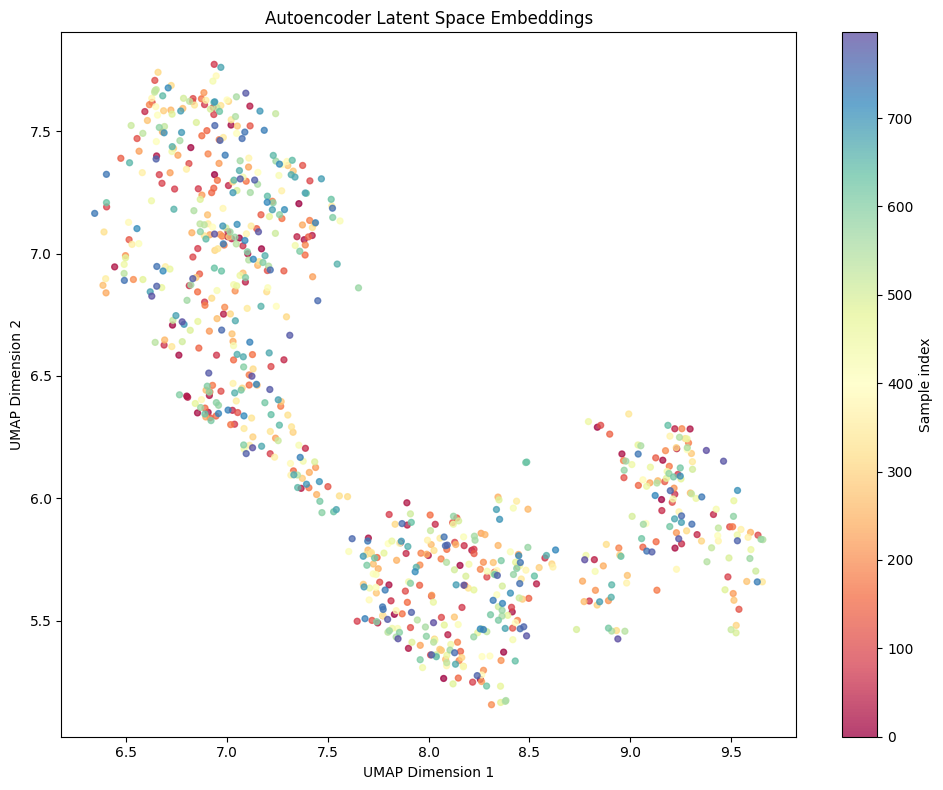

In [15]:
# Visualize the latent embedding space with UMAP
model.eval()
latent_embeddings = []
sample_names = []

with torch.no_grad():
    for images, names in train_loader:
        images = images.to(DEVICE)
        embeddings = model.encode(images)
        embeddings = embeddings.reshape(embeddings.size(0), -1)
        latent_embeddings.append(embeddings.cpu().numpy())
        sample_names.extend(list(names))

latent_embeddings = np.concatenate(latent_embeddings, axis=0)
sample_names = np.asarray(sample_names)

reducer = umap.UMAP(
    n_components=6, 
    n_neighbors=15,      # Increased to see more global relationships
    min_dist=0.01,       # Decreased to pack clusters tightly
    metric='cosine',     # Often better for neural network embeddings
    random_state=42
)
reduced_embeddings = reducer.fit_transform(latent_embeddings)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    reduced_embeddings[:, 0],
    reduced_embeddings[:, 1],
    c=np.arange(len(sample_names)),
    cmap='Spectral',
    s=18,
    alpha=0.75,
)
plt.colorbar(scatter, label='Sample index')
plt.title('Autoencoder Latent Space Embeddings')
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.tight_layout()
plt.show()

## Reconstruction results

Visualize example persistence images before and after the autoencoder reconstruction. This gives intuition on what the model learned in the compressed latent space.

<Figure size 1200x400 with 0 Axes>

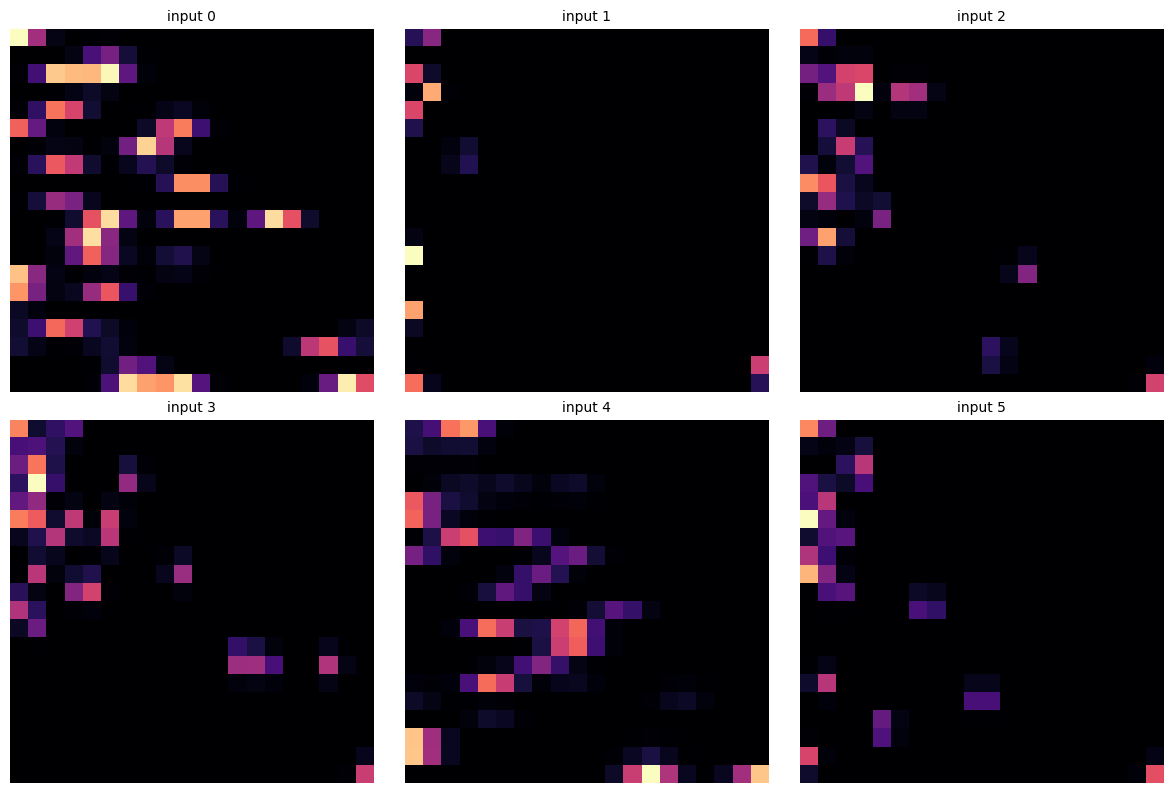

<Figure size 1200x400 with 0 Axes>

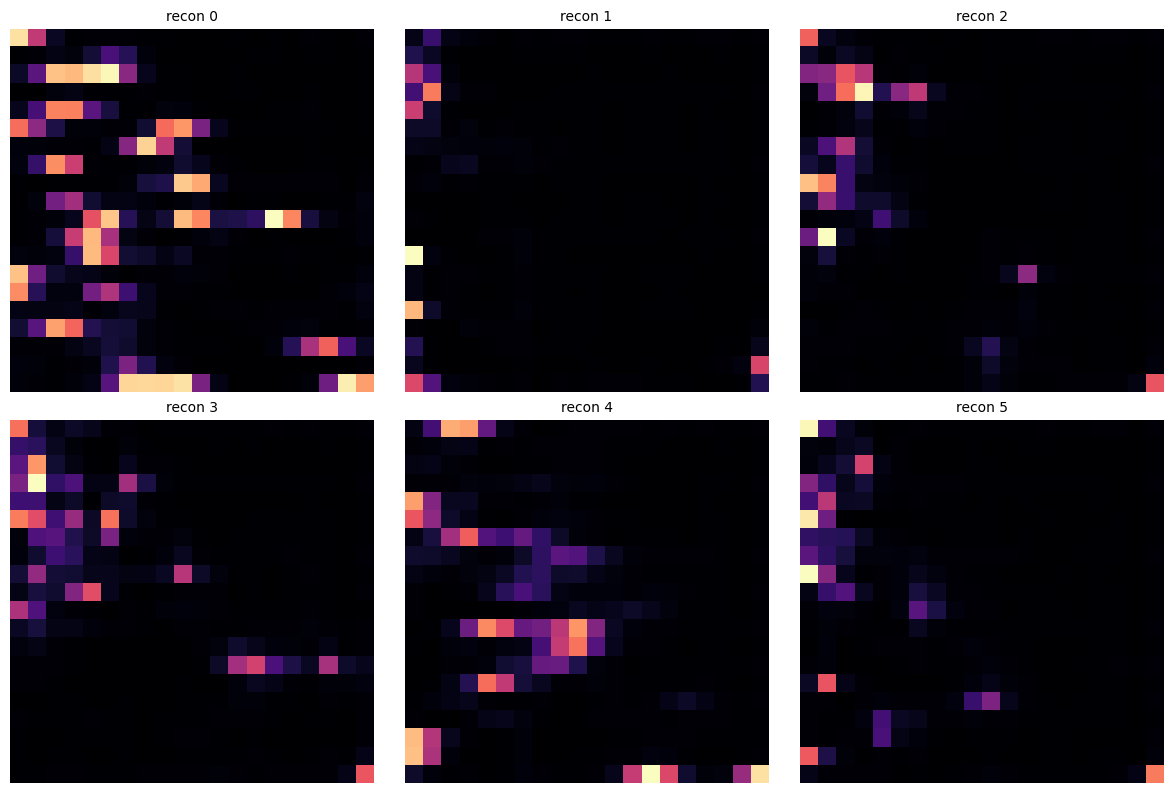

In [29]:
model.eval()
with torch.no_grad():
    batch, filenames = next(iter(train_loader))
    batch = batch.to(DEVICE)
    recon = model(batch)
    inputs = batch.cpu().numpy()
    outputs = recon.cpu().numpy()

n_display = min(6, inputs.shape[0])

# Create input visualization
fig_input = plt.figure(figsize=(12, 4))
plot_image_grid([inputs[i] for i in range(n_display)], titles=[f'input {i}' for i in range(n_display)], ncols=3)
wandb.log({"reconstruction_inputs": wandb.Image(fig_input)})

# Create reconstruction visualization
fig_recon = plt.figure(figsize=(12, 4))
plot_image_grid([outputs[i] for i in range(n_display)], titles=[f'recon {i}' for i in range(n_display)], ncols=3)
wandb.log({"reconstruction_outputs": wandb.Image(fig_recon)})


## Inspect encoded feature maps

Show the encoder activations for one example image. These compressed feature maps are the internal representation learned by the autoencoder.

Encoded feature map shape: (128, 5, 5)


<Figure size 1200x400 with 0 Axes>

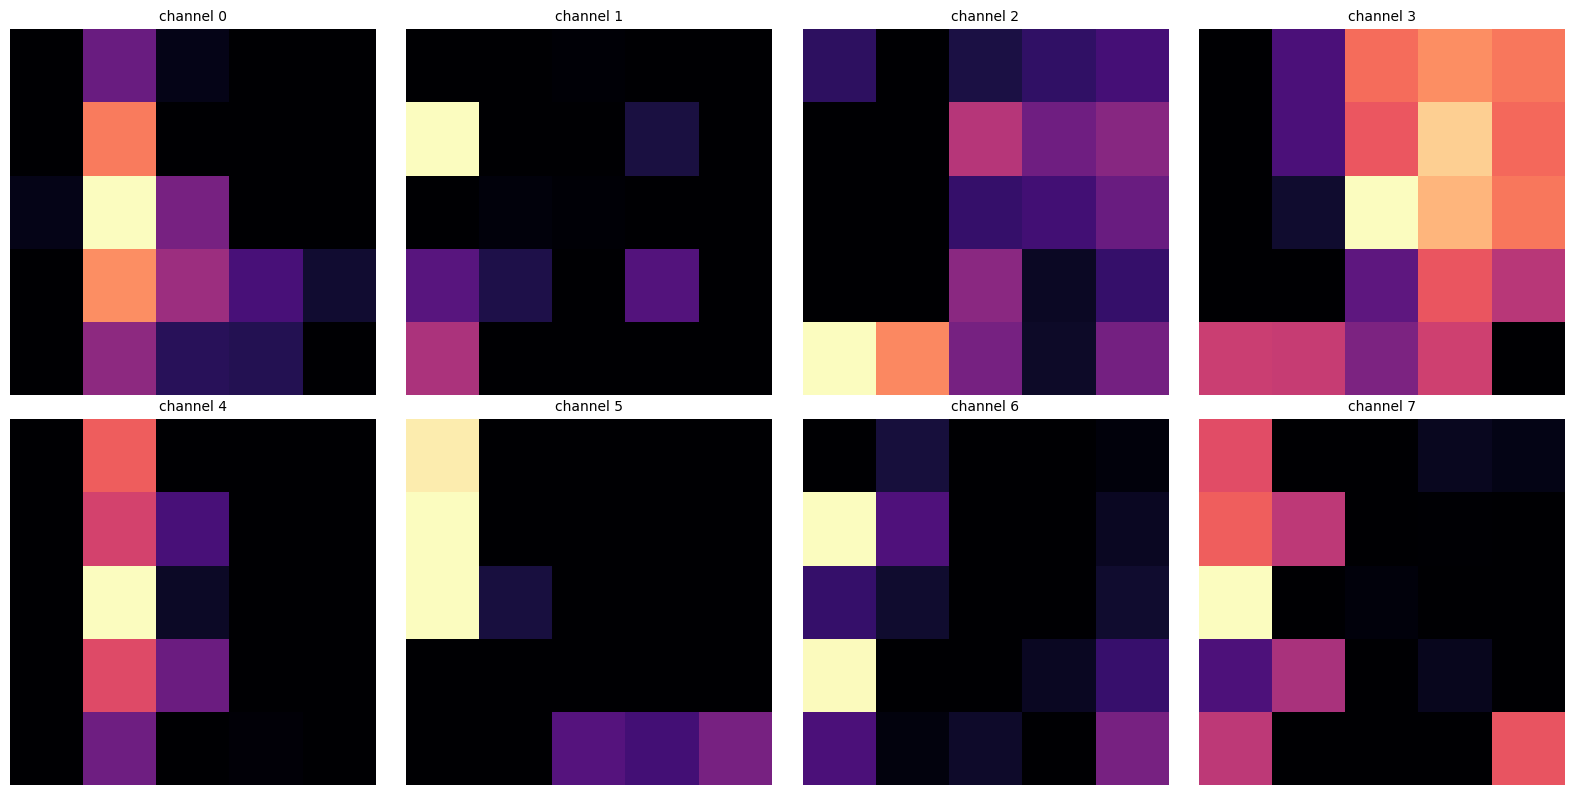

In [30]:
with torch.no_grad():
    batch, _ = next(iter(train_loader))
    encoded = model.encode(batch.to(DEVICE))
    encoded = encoded.cpu().numpy()

encoded_maps = encoded[0]
print('Encoded feature map shape:', encoded_maps.shape)

fig_encoded = plt.figure(figsize=(12, 4))
plot_image_grid([encoded_maps[i] for i in range(min(encoded_maps.shape[0], 8))],
                titles=[f'channel {i}' for i in range(min(encoded_maps.shape[0], 8))],
                ncols=4)
wandb.log({"encoded_feature_maps": wandb.Image(fig_encoded)})


## Save the model and sample outputs

Persist the trained model weights and example reconstructions in a local output folder. If you want, you can later load the saved `.pth` file from another notebook or script.

In [31]:
output_dir = workspace_root / 'results' / 'autoencoder_persistence_image'
output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / 'conv_autoencoder_persistence_image.pth'
torch.save(model.state_dict(), model_path)
np.save(output_dir / 'sample_input.npy', inputs[0])
np.save(output_dir / 'sample_reconstruction.npy', outputs[0])
print('Saved model to', model_path)
print('Saved sample input and reconstruction to', output_dir)

# Save model to W&B
wandb.save(str(model_path))

# Log final metrics
wandb.log({
    "final_loss": train_losses[-1],
    "total_epochs": n_epochs,
    "model_parameters": sum(p.numel() for p in model.parameters()),
})

# Save sample predictions as table for easy browsing
sample_table = wandb.Table(columns=["input", "reconstruction", "mse_error"])
for i in range(min(6, inputs.shape[0])):
    mse = np.mean((inputs[i] - outputs[i]) ** 2)
    sample_table.add_data(
        wandb.Image(inputs[i]),
        wandb.Image(outputs[i]),
        float(mse)
    )
wandb.log({"sample_reconstructions": sample_table})

# Finish W&B run
wandb.finish()
print("W&B run completed and uploaded!")


wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.


Saved model to /Users/ploypusee/Library/CloudStorage/GoogleDrive-ploy.polyluna@gmail.com/My Drive/2 Work/Research/01 Active Project/TDA Cell Classification/results/autoencoder_persistence_image/conv_autoencoder_persistence_image.pth
Saved sample input and reconstruction to /Users/ploypusee/Library/CloudStorage/GoogleDrive-ploy.polyluna@gmail.com/My Drive/2 Work/Research/01 Active Project/TDA Cell Classification/results/autoencoder_persistence_image


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
final_loss,▁
model_parameters,▁
total_epochs,▁
train_loss,█▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,20
final_loss,0.00131
model_parameters,134657
total_epochs,20
train_loss,0.00131


W&B run completed and uploaded!
